# JS09 – Klasifikasi: Praktikum 3
## Klasifikasi SMS Spam dengan Multinomial Naive Bayes

**Tujuan praktikum**

1. Melakukan praproses data teks SMS.
2. Mengubah teks menjadi fitur numerik dengan **Bag of Words** (`CountVectorizer`).
3. Melatih **Multinomial Naive Bayes** untuk klasifikasi `spam` vs `ham`.
4. Mengevaluasi model dengan akurasi, precision, recall, F1-score, dan confusion matrix.
5. Menganalisis kata-kata yang paling berpengaruh terhadap prediksi spam.

**Dataset:** `spam.csv` berisi 5.572 baris SMS berlabel `ham` (bukan spam) atau `spam`. Setelah **403 SMS duplikat identik** dihapus, data yang dianalisis berjumlah **5.169 SMS unik** (4.516 ham dan 653 spam). Dataset asli memiliki lima kolom, tetapi tiga kolom terakhir sebagian besar kosong dan tidak dipakai.

> Pada klasifikasi teks, **data leakage** mudah terjadi jika `CountVectorizer` di-fit pada seluruh data sebelum split. Karena itu, vectorizer hanya di-fit pada data latih, lalu digunakan untuk mentransformasi data uji. Duplikat juga dihapus sebelum split agar pesan yang sama tidak muncul di data latih dan data uji sekaligus.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_colwidth", 100)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membaca data

Encoding `latin-1` diperlukan karena file CSV tidak sepenuhnya menggunakan UTF-8.

In [2]:
df = pd.read_csv("spam.csv", encoding="latin-1")

print("Ukuran data:", df.shape)
df.head()

Ukuran data: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


### 2. Membersihkan kolom dan mengganti nama

Tiga kolom terakhir (`Unnamed: 2`, `Unnamed: 3`, `Unnamed: 4`) dibuang karena hampir seluruh nilainya kosong. Kolom `v1` diganti menjadi `Labels` dan `v2` menjadi `SMS`.

In [3]:
df = df.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"])
df = df.rename(columns={"v1": "Labels", "v2": "SMS"})

print("Ukuran setelah pembersihan:", df.shape)
df.head()

Ukuran setelah pembersihan: (5572, 2)


,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


### 3. Inspeksi data

In [4]:
print("Jumlah SMS per kelas:")
print(df["Labels"].value_counts())
print("\nProporsi kelas (%):")
print((df["Labels"].value_counts(normalize=True) * 100).round(2))

Jumlah SMS per kelas:
Labels
ham     4825
spam     747
Name: count, dtype: int64

Proporsi kelas (%):
Labels
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Labels  5572 non-null   str  
 1   SMS     5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [6]:
print("Jumlah nilai kosong:")
print(df.isna().sum())
print("\nJumlah SMS duplikat:", df["SMS"].duplicated().sum())
print("\nStatistik panjang SMS (jumlah karakter):")
print(df["SMS"].str.len().describe())

Jumlah nilai kosong:
Labels    0
SMS       0
dtype: int64

Jumlah SMS duplikat: 403

Statistik panjang SMS (jumlah karakter):
count    5572.000000
mean       80.118808
std        59.690841
min         2.000000
25%        36.000000
50%        61.000000
75%       121.000000
max       910.000000
Name: SMS, dtype: float64


### 4. Encoding label

Label diubah menjadi angka: `spam = 1`, `ham = 0`. Ini memudahkan perhitungan metrik klasifikasi biner.

In [7]:
df["Labels"] = df["Labels"].map({"spam": 1, "ham": 0})

print(df["Labels"].value_counts())
df.head()

Labels
0    4825
1     747
Name: count, dtype: int64


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives around here though"


In [8]:
print("Sebelum deduplikasi:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("Setelah deduplikasi:", df.shape)

Sebelum deduplikasi: (5572, 2)
Setelah deduplikasi: (5169, 2)


Terdapat **403 SMS duplikat identik**. Duplikat dihapus sebelum pemodelan agar pesan yang sama tidak muncul di data latih dan data uji sekaligus (mencegah kebocoran informasi). Setelah deduplikasi tersisa **5.169 SMS unik**: 4.516 ham dan 653 spam.

### 5. Eksplorasi panjang SMS

Panjang pesan dapat menjadi indikasi awal: SMS spam cenderung lebih panjang karena berisi penawaran, tautan, atau instruksi. Namun, fitur utama model tetap berasal dari kata-kata di dalam SMS.

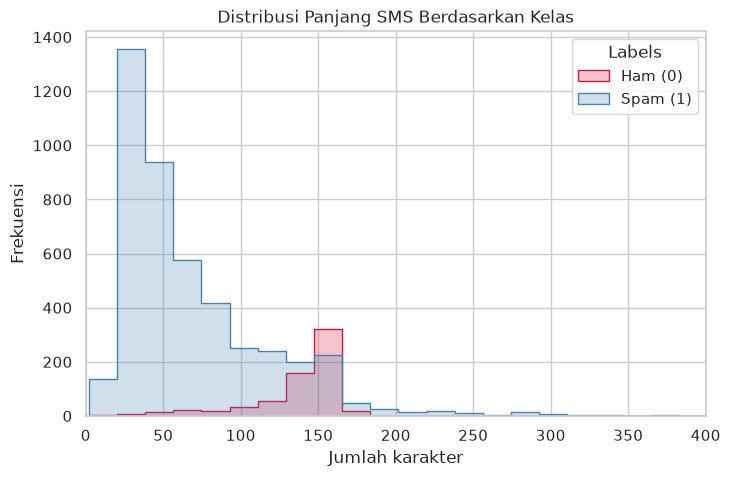

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x=df["SMS"].str.len(),
    hue="Labels",
    bins=50,
    palette={0: "steelblue", 1: "crimson"},
    element="step",
)
plt.title("Distribusi Panjang SMS Berdasarkan Kelas")
plt.xlabel("Jumlah karakter")
plt.ylabel("Frekuensi")
plt.legend(title="Labels", labels=["Ham (0)", "Spam (1)"])
plt.xlim(0, 400)
plt.show()

### 6. Pembagian data dan ekstraksi fitur

Data dibagi **80% latih dan 20% uji** dengan `random_state=50` dan `stratify=y` agar proporsi spam/ham pada data uji mirip dengan data asli.

`CountVectorizer` membentuk kosakata dari data latih, menghitung frekuensi setiap kata, lalu menghasilkan matriks sparse berukuran `jumlah_dokumen × jumlah_kata`.

In [10]:
X = df["SMS"].values
y = df["Labels"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=50,
    stratify=y,
)

print("Data latih :", len(X_train), "SMS")
print("Data uji   :", len(X_test), "SMS")
print("Distribusi kelas latih:", np.bincount(y_train))
print("Distribusi kelas uji  :", np.bincount(y_test))

Data latih : 4135 SMS
Data uji   : 1034 SMS
Distribusi kelas latih: [3613  522]
Distribusi kelas uji  : [903 131]


In [11]:
bow = CountVectorizer()

X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)

jumlah_kata = len(bow.get_feature_names_out())
sparsity = X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1])

print("Jumlah kata dalam kosakata:", jumlah_kata)
print("Dimensi X_train:", X_train_bow.shape)
print("Dimensi X_test :", X_test_bow.shape)
print(f"Sparsity X_train: {sparsity:.4%} nilai bukan nol")
print("\nContoh 20 kata dalam kosakata:")
print(list(bow.get_feature_names_out())[:20])

Jumlah kata dalam kosakata: 7623
Dimensi X_train: (4135, 7623)
Dimensi X_test : (1034, 7623)
Sparsity X_train: 0.1724% nilai bukan nol

Contoh 20 kata dalam kosakata:
['00', '000', '000pes', '008704050406', '0089', '0121', '01223585236', '01223585334', '0125698789', '02', '0207', '02072069400', '02073162414', '02085076972', '03', '04', '0430', '05', '050703', '06']


### 7. Melatih Multinomial Naive Bayes

In [12]:
mnb = MultinomialNB()
mnb.fit(X_train_bow, y_train)

y_pred_train = mnb.predict(X_train_bow)
y_pred_test = mnb.predict(X_test_bow)

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"Akurasi data latih: {acc_train:.4f}")
print(f"Akurasi data uji  : {acc_test:.4f}")

Akurasi data latih: 0.9935
Akurasi data uji  : 0.9816


In [13]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_test))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred_test, target_names=["ham", "spam"], digits=4))

Confusion Matrix:
[[898   5]
 [ 14 117]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

         ham     0.9846    0.9945    0.9895       903
        spam     0.9590    0.8931    0.9249       131

    accuracy                         0.9816      1034
   macro avg     0.9718    0.9438    0.9572      1034
weighted avg     0.9814    0.9816    0.9813      1034



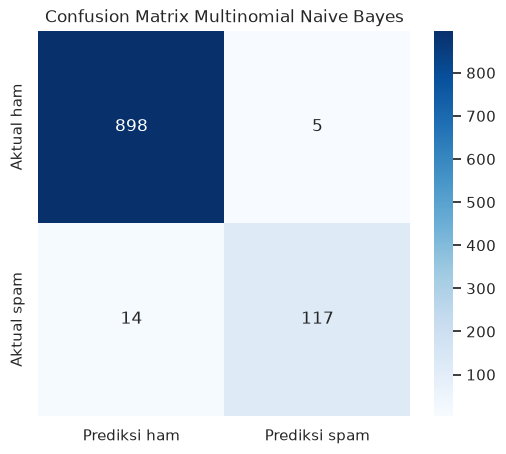

In [14]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Prediksi ham", "Prediksi spam"],
    yticklabels=["Aktual ham", "Aktual spam"],
)
plt.title("Confusion Matrix Multinomial Naive Bayes")
plt.show()

### 8. Validasi silang 5-fold

Satu split data uji bisa memberikan hasil yang kebetulan baik atau buruk. Validasi silang 5-fold pada seluruh data memberikan estimasi yang lebih stabil. Pipeline memastikan `CountVectorizer` di-fit ulang di dalam setiap fold, sehingga tidak ada kebocoran informasi.

In [15]:
pipeline_nb = Pipeline([
    ("bow", CountVectorizer()),
    ("nb", MultinomialNB()),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    pipeline_nb, X, y, cv=cv, scoring="accuracy", n_jobs=-1
)

print("Akurasi setiap fold:", np.round(cv_scores, 4))
print(f"Rata-rata akurasi CV: {cv_scores.mean():.4f}")
print(f"Simpangan baku      : {cv_scores.std():.4f}")

Akurasi setiap fold: [0.9836 0.9865 0.9826 0.9855 0.9903]
Rata-rata akurasi CV: 0.9857
Simpangan baku      : 0.0027


### 9. Kata yang paling berpengaruh

`MultinomialNB` menyimpan log probabilitas setiap kata untuk kelas `ham` dan `spam`. Selisih log probabilitas menunjukkan kata yang lebih khas untuk spam (nilai positif besar) atau ham (nilai negatif besar).

In [16]:
feature_names = np.array(bow.get_feature_names_out())
log_diff = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]

top_spam_idx = np.argsort(log_diff)[-15:][::-1]
top_ham_idx = np.argsort(log_diff)[:15]

top_words = pd.DataFrame({
    "Kata khas SPAM": feature_names[top_spam_idx],
    "Skor": log_diff[top_spam_idx],
})
top_words.round(3)

,Kata khas SPAM,Skor
0,claim,5.405
1,prize,5.245
2,150p,5.018
3,18,4.700
4,tone,4.700
5,guaranteed,4.537
6,www,4.461
7,1000,4.412
8,cs,4.412
9,500,4.378


In [17]:
top_ham = pd.DataFrame({
    "Kata khas HAM": feature_names[top_ham_idx],
    "Skor": log_diff[top_ham_idx],
})
top_ham.round(3)

,Kata khas HAM,Skor
0,gt,-4.478
1,lt,-4.474
2,he,-4.171
3,lor,-3.938
4,da,-3.717
5,she,-3.643
6,ì_,-3.533
7,come,-3.438
8,later,-3.432
9,where,-3.408


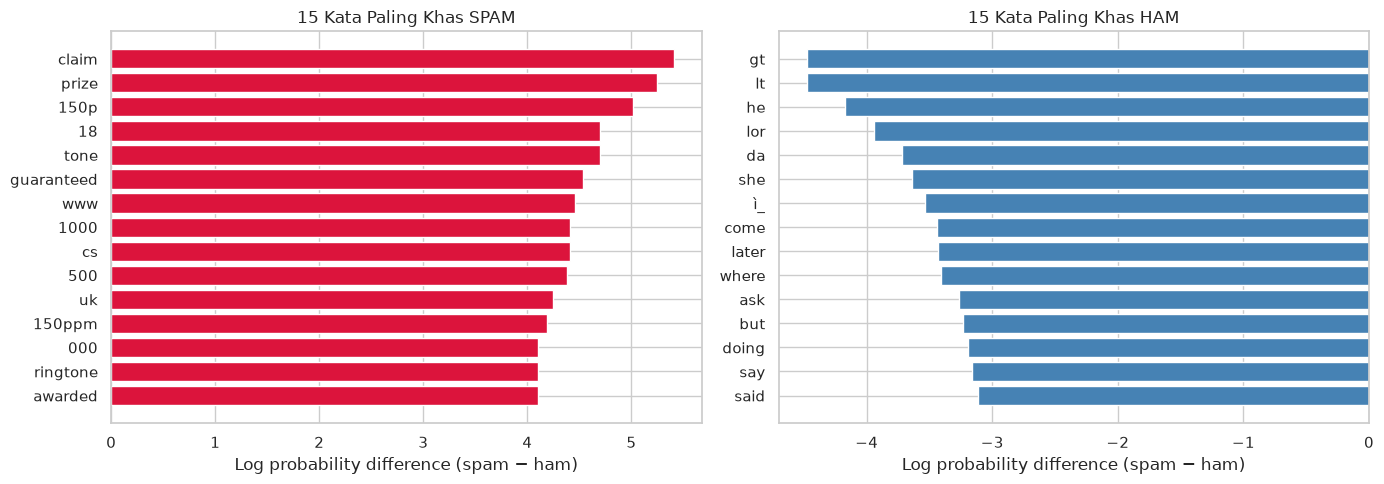

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(
    top_words["Kata khas SPAM"][::-1],
    top_words["Skor"][::-1],
    color="crimson",
)
axes[0].set_title("15 Kata Paling Khas SPAM")
axes[0].set_xlabel("Log probability difference (spam − ham)")

axes[1].barh(
    top_ham["Kata khas HAM"][::-1],
    top_ham["Skor"][::-1],
    color="steelblue",
)
axes[1].set_title("15 Kata Paling Khas HAM")
axes[1].set_xlabel("Log probability difference (spam − ham)")

plt.tight_layout()
plt.show()

### 10. Interpretasi hasil

**Performa model**

- Akurasi data latih: **0,9935**
- Akurasi data uji: **0,9816**
- Precision spam: **0,9590**
- Recall spam: **0,8931**
- F1-score spam: **0,9249**
- Rata-rata akurasi 5-fold CV: **0,9857**

Confusion matrix menunjukkan **5 ham yang salah diprediksi sebagai spam** (false positive) dan **14 spam yang lolos sebagai ham** (false negative). Recall spam lebih rendah daripada precision karena model lebih berhati-hati dalam memberi label spam. Pada kasus nyata, biaya false positive dan false negative perlu dipertimbangkan: memblokir SMS penting (false positive) bisa lebih merugikan daripada membiarkan satu spam lolos.

**Mengapa CountVectorizer cocok?**

- Setiap kata menjadi fitur diskrit (jumlah kemunculan), sesuai asumsi Multinomial Naive Bayes.
- Matriks sangat sparse (hanya sebagian kecil kata yang muncul di setiap SMS), dan Naive Bayes menangani dimensi tinggi dengan baik.
- Kata-kata khas spam seperti penawaran, hadiah, tautan, dan instruksi balas pesan memberikan sinyal yang kuat.

**Keterbatasan**

- Bag of Words mengabaikan urutan kata dan konteks kalimat.
- Kata-kata umum yang tidak masuk stop word tetap menjadi fitur; beberapa di antaranya bisa menjadi noise.
- Dataset tidak seimbang (spam hanya sekitar 12,6%), sehingga akurasi saja bisa menyesatkan; precision, recall, dan F1 harus dilihat bersama.
- Satu split data uji tidak cukup untuk klaim performa; validasi silang membantu, tetapi tetap bergantung pada distribusi data.
- Duplikat dihapus pada eksperimen ini; jika duplikat dibiarkan, evaluasi bisa menjadi lebih optimistis karena pesan yang sama berpotensi muncul di data latih dan data uji.

**Kesimpulan**

1. Multinomial Naive Bayes dengan CountVectorizer mencapai akurasi uji **98,16%** dan F1 spam **0,925**.
2. Model sangat baik mengenali spam (precision tinggi), tetapi masih melewatkan sekitar **10,7%** spam (recall 89,31%).
3. Fitur kata diskrit dan asumsi independensi Naive Bayes bekerja efektif untuk klasifikasi teks SMS.
4. Untuk pengembangan lebih lanjut, dapat dicoba TF-IDF, penghapusan stop words, tuning `alpha`, atau model linear seperti Logistic Regression.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS09 – Klasifikasi, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi
- `scikit-learn` – Working with text data. https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html
- `scikit-learn` – Multinomial Naive Bayes. https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
- Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.